<div align=center>
<h1>Évaluation des modèles d'apprentissage machine</h1>
</div>

<img src="bcw.png">

PLAN :
1. <a href="#pipeline">Écriture d'une chaine de traitement dans un Pipeline</a>
2. <a href="#crossvalidation">Évaluation de la performance du modèle par validation croisée</a>
3. <a href="#learningcurve">Établir un diagnostic sur les biais et variances du modèle avec des courbes d'apprentissage (learning curves)</a>
4. <a href="#validationcurve">Analyse du risque de sous/sur apprentissage avec les courbes de validation</a>
5. <a href="#gridsearch">Réglage des hyperparamètres via une recherche par grille (Grid Search)</a>
6. <a href="#nestedcv">Réglage fin d'un modèle par validation croisée imbriquée (*nested cross-validation)</a>
7. <a href="#metrics">Les différentes métriques de la performance d'un modèle prédictif</a>

## Les données du lab

**Data Set Information:**  
Features are computed from a digitized image of a fine needle aspirate (FNA) of a breast mass. They describe characteristics of the cell nuclei present in the image. A few of the images can be found at [Web Link] 

Separating plane described above was obtained using Multisurface Method-Tree (MSM-T) [K. P. Bennett, "Decision Tree Construction Via Linear Programming." Proceedings of the 4th Midwest Artificial Intelligence and Cognitive Science Society, pp. 97-101, 1992], a classification method which uses linear programming to construct a decision tree. Relevant features were selected using an exhaustive search in the space of 1-4 features and 1-3 separating planes. 

The actual linear program used to obtain the separating plane in the 3-dimensional space is that described in: [K. P. Bennett and O. L. Mangasarian: "Robust Linear Programming Discrimination of Two Linearly Inseparable Sets", Optimization Methods and Software 1, 1992, 23-34]. 

This database is also available through the UW CS ftp server: 
ftp ftp.cs.wisc.edu 
cd math-prog/cpo-dataset/machine-learn/WDBC/


**Attribute Information:**

    1) ID number 
    2) Diagnosis (M = malignant, B = benign) 
    3-32) (3D) Ten real-valued features are computed for each cell nucleus: 
        a) radius (mean of distances from center to points on the perimeter) 
        b) texture (standard deviation of gray-scale values) 
        c) perimeter 
        d) area 
        e) smoothness (local variation in radius lengths) 
        f) compactness (perimeter^2 / area - 1.0) 
        g) concavity (severity of concave portions of the contour) 
        h) concave points (number of concave portions of the contour) 
        i) symmetry 
        j) fractal dimension ("coastline approximation" - 1)

#### Chargement des données

In [1]:
import pandas as pd
df = pd.read_csv('https://archive.ics.uci.edu/ml/'
                 'machine-learning-databases'
                 '/breast-cancer-wisconsin/wdbc.data', header=None)
df.head()

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
df.shape

(569, 32)

#### Pré-traitement

##### Sélection des variables prédictives
Note : sous pandas, loc et iloc sélectionnent premièrement par colonne et indexes (resp.) ; iloc n'accepte que des entiers pour les indexes

In [3]:
X = df.loc[:, 2:].values
y = df.loc[:,1].values

##### Encodage du label

In [4]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y = le.fit_transform(y)
le.classes_

array(['B', 'M'], dtype=object)

*Vérif :*

In [5]:
le.transform(['M', 'B'])

array([1, 0])

##### Partitionnement des données

In [6]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = \
    train_test_split(X, y, 
                     test_size=0.20, 
                     stratify=y,
                     random_state=1)

## Écriture d'une chaine de traitement dans un Pipeline
Combinaison de *transformers* et d' *estimators* dans un *pipeline*

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# Construction du pipeline
pipe_lr = make_pipeline(StandardScaler(),
                       PCA(n_components=2),
                       LogisticRegression(solver='liblinear', multi_class='ovr',random_state=1))

# Application du pipeline aux données d'entrainement
pipe_lr.fit(X_train, y_train)

# Estimation sur les données de test
y_pred = pipe_lr.predict(X_test)

# Affichage de la performance du modèle construit
print('Précision sur les données Test : %.3f' %
     pipe_lr.score(X_test, y_test))

Précision sur les données Test : 0.956


<a id='crossvalidation'></a>

## Évaluation de la performance du modèle par validation croisée

In [8]:
from sklearn.model_selection import cross_val_score
import numpy as np
scores = cross_val_score(estimator=pipe_lr,
                         X=X_train,
                         y=y_train,
                         cv=10,
                         n_jobs=1)
print('CV accuracy scores: %s' % scores)
print('CV accuracy: %3.10f +/- %3.10f' % (np.mean(scores), np.std(scores)))

CV accuracy scores: [0.93478261 0.93478261 0.95652174 0.95652174 0.93478261 0.95555556
 0.97777778 0.93333333 0.95555556 0.95555556]
CV accuracy: 0.9495169082 +/- 0.0138542942


*On voit que la valeur de performance prédite avec les données tests de l'étape précédente est bien incluse dans l'interval de performance trouvée ici. Pourtant on n'a utilisé que les données train, ce qui prouve l'intérêt de cette méthode d'évaluation*

<a id='learningcurve'></a>

## Établir un diagnostic sur les biais et variances du modèle avec des courbes d'apprentissage (*learning curves*)

In [9]:
# Si besoin, faire :
#from sklearn.model_selection import learning_curve
#?learning_curve

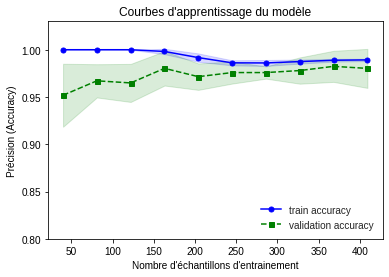

In [10]:
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.model_selection import learning_curve

# Construction d'un pipeline simple (sans ACP)
pipe_lr = make_pipeline(StandardScaler(),
                       LogisticRegression(solver='liblinear', multi_class='ovr',
                                          penalty='l2', random_state=1))

# Réalisation d'une courbe d'apprentissage basée sur 
# ce pipeline
train_sizes, train_scores, test_scores = \
    learning_curve(estimator=pipe_lr,
                  X=X_train,
                  y=y_train,
                   # échantillonage du jeux de données
                   # d'entrainement 1% à 100% (10 valeurs)
                  train_sizes=np.linspace(0.1,1.0,10),
                   # utilisation d'un CV à 10 partitions
                  cv=10
                   # pour le parallélisme
                   #n_jobs=1
                  )

# Préparation des données pour l'affichage
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Affichage de la courbe d'entrainement : 
# train_score_moyen = f( taille des données train )
plt.plot(train_sizes, train_mean,
        color='blue', marker='o',
        markersize=5, label='train accuracy')

# Affichage des écarts types sur les scores de la CV
# correspondants
plt.fill_between(train_sizes,
                train_mean + train_std,
                train_mean - train_std,
                alpha=0.15, color='blue')

# Affichage de la courbe de validation :
# test_mean = f( train_sizes )
plt.plot(train_sizes, test_mean,
         color='green', linestyle='--',
         marker='s', markersize=5, 
         label='validation accuracy')

# Affichage des écarts types sur les scores de la CV
# correspondants
plt.fill_between(train_sizes,
                test_mean + test_std,
                test_mean - test_std,
                alpha=0.15, color='green')

# Paramètres d'affichages généraux
mpl.style.use('seaborn')
plt.title('Courbes d\'apprentissage du modèle')
plt.xlabel('Nombre d\'échantillons d\'entrainement')
plt.ylabel('Précision (Accuracy)')
plt.legend(loc='lower right')
plt.ylim(0.8, 1.03)
plt.tight_layout
#plt.savefig('images/06_05.png', dpi=300)
plt.show()

On voit que :
- le modèle donne de bons résultats tant pour les données d'entrainement que pour les données de test à partir d'une taille des données d'entrainement de ~ 250 ;
- on constate qu'avant le nombre d'échantillons est insuffisant et qu'il conduit à un surapprentissage du modèle qui ne généralise pas bien, les écarts entre les deux courbes est conséquent.

<a id='validationcurve'></a>

## Analyse du risque de sous/sur apprentissage avec les courbes de validation

Liste des paramêtres du pipeline :

In [11]:
pipe_lr.get_params()

{'memory': None,
 'steps': [('standardscaler', StandardScaler()),
  ('logisticregression',
   LogisticRegression(multi_class='ovr', random_state=1, solver='liblinear'))],
 'verbose': False,
 'standardscaler': StandardScaler(),
 'logisticregression': LogisticRegression(multi_class='ovr', random_state=1, solver='liblinear'),
 'standardscaler__copy': True,
 'standardscaler__with_mean': True,
 'standardscaler__with_std': True,
 'logisticregression__C': 1.0,
 'logisticregression__class_weight': None,
 'logisticregression__dual': False,
 'logisticregression__fit_intercept': True,
 'logisticregression__intercept_scaling': 1,
 'logisticregression__l1_ratio': None,
 'logisticregression__max_iter': 100,
 'logisticregression__multi_class': 'ovr',
 'logisticregression__n_jobs': None,
 'logisticregression__penalty': 'l2',
 'logisticregression__random_state': 1,
 'logisticregression__solver': 'liblinear',
 'logisticregression__tol': 0.0001,
 'logisticregression__verbose': 0,
 'logisticregression__wa

Le paramètre important dans la régression logistique est **C, 'logisticregression__C'** (inversement proportionnel à la régularisation dans la fonction de coût du model.

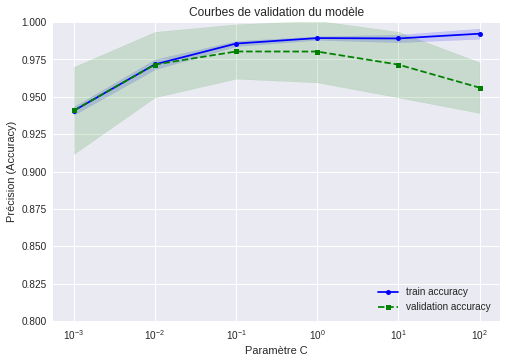

In [12]:
from sklearn.model_selection import validation_curve

# balayage du paramètre C 
# [surrégularisation ... sousrégularisation]
param_range = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]

# Construction de la oourbe de validation
train_scores, test_scores = validation_curve(
    estimator=pipe_lr,
    X=X_train,
    y=y_train,
    param_name='logisticregression__C',
    param_range=param_range,
    cv=10)

# [ibid précédente, avec param_range à la place de train_sizes]
# Préparation des données des courbes 
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Affichage de la courbe d'entrainement : 
# train_score_moyen = f( param_range )
plt.plot(param_range, train_mean,
        color='blue', marker='o',
        markersize=5, label='train accuracy')

# Affichage des écarts types sur les scores de la CV
# correspondants
plt.fill_between(param_range,
                train_mean + train_std,
                train_mean - train_std,
                alpha=0.15, color='blue')

# Affichage de la courbe de validation :
# test_mean = f( param_range )
plt.plot(param_range, test_mean,
         color='green', linestyle='--',
         marker='s', markersize=5, 
         label='validation accuracy')

# Affichage des écarts types sur les scores de la CV
# correspondants
plt.fill_between(param_range,
                test_mean + test_std,
                test_mean - test_std,
                alpha=0.15, color='green')

# Paramètres d'affichages généraux
mpl.style.use('seaborn')
plt.title('Courbes de validation du modèle')
# mise en log de l'axe des X
plt.xscale('log')
plt.xlabel('Paramètre C')
plt.ylabel('Précision (Accuracy)')
plt.legend(loc='lower right')
plt.ylim(0.8, 1.0)
plt.tight_layout
#plt.savefig('images/06_05.png', dpi=300)
plt.show()


On voit que pour de faibles valeurs de C (forte régularisation) le modèle tends vers du sous apprentissage (la précision décroit) alors que pour de fortes valeurs de C (faible régularisation) le modèle tends vers du surapprentissage (la courbe train tends vers 1, alors que la courbe test décroit). Ainsi **la valeur idéale de C se trouve entre 0.01 et 0.1**.

<a id='gridsearch'></a>

## Réglage des hyperparamètres via une recherche par grille (Grid Search)

**Construction d'un nouveau pipeline** avec un algorithme de prédiction (SVM) qui comporte plusieurs paramètres importants :

In [13]:
from sklearn.svm import SVC
pipe_svc = make_pipeline(StandardScaler(),
                        SVC(random_state=1, probability=True))

**Affichage de la liste des paramètres du pipeline :**

In [14]:
pipe_svc.get_params()

{'memory': None,
 'steps': [('standardscaler', StandardScaler()),
  ('svc', SVC(probability=True, random_state=1))],
 'verbose': False,
 'standardscaler': StandardScaler(),
 'svc': SVC(probability=True, random_state=1),
 'standardscaler__copy': True,
 'standardscaler__with_mean': True,
 'standardscaler__with_std': True,
 'svc__C': 1.0,
 'svc__break_ties': False,
 'svc__cache_size': 200,
 'svc__class_weight': None,
 'svc__coef0': 0.0,
 'svc__decision_function_shape': 'ovr',
 'svc__degree': 3,
 'svc__gamma': 'scale',
 'svc__kernel': 'rbf',
 'svc__max_iter': -1,
 'svc__probability': True,
 'svc__random_state': 1,
 'svc__shrinking': True,
 'svc__tol': 0.001,
 'svc__verbose': False}

**Construction d'une recherche par grille sur les paramètres suivants :**
- svc__C (le paramètre de régularisation / inverse)
- svc__kernel (le type de noyau, kernel, choisi)
- svc__gamma (le paramètre de tension du kernel / inverse écart type)

In [15]:
from sklearn.model_selection import GridSearchCV
# Spécification du balayage de grille
param_range = [0.0001, 0.001, 0.01, 0.1, 1.0, 10.0, 
               100.0, 1000.0]

# Spécification des paramètres de la grille
# rq : on entre une liste de dictionnaires python
param_grid = [{'svc__C' : param_range,
               'svc__kernel': ['linear']},
              {'svc__C': param_range,
               'svc__gamma': param_range,
               'svc__kernel': ['rbf']}]

# Création du GridSearch
gs = GridSearchCV(estimator=pipe_svc,
                  param_grid=param_grid,
                  scoring='accuracy',
                  cv=10,
                  n_jobs=-1) # parallélisation

# Application du GridSearch aux données d'entrainement
gs = gs.fit(X_train, y_train)
print('\nMeilleur Précision (Accuracy) : ', gs.best_score_)
print('Meilleurs paramètres : ',gs.best_params_)


Meilleur Précision (Accuracy) :  0.9846859903381642
Meilleurs paramètres :  {'svc__C': 100.0, 'svc__gamma': 0.001, 'svc__kernel': 'rbf'}


**Récupération du meilleur paramètrage du modèle et test de sa Précision :**

In [16]:
clf = gs.best_estimator_
#clf.fit(X_train, y_train)
print('Test de précision (accuracy): %.3f' % 
      clf.score(X_test, y_test))

Test de précision (accuracy): 0.974


*Remarque : l'utilisation du GridSearch est très consommateur de temps de calcul et peut devenir incompatble pour le big data, aussi on utilise une fonction de tirage aléatoire des paramètres, **RandomizedSearch***

<a id='nestedcv'></a>

## Réglage fin d'un modèle par validation croisée imbriquée (*nested cross-validation*)

### Application à un SVM

In [47]:
# Choix des nbres de dossiers pour les deux boucles
size = X.shape[0]
print("Taille du fichier data : ",size)
cvout = 10
cvint = 5
print("Taille des fichiers (train, test) pour,")
testout = size // cvout
testint = testout*(cvout-1) // cvint
print("- Boucle externe   : ",((cvout-1)*testout,testout))
print("- Boucles internes : ",((cvint-1)*testint,testint))
print("=> Nbre de modèles %d x combinatoire du gridSearch\n" %(cvout*cvint))

Taille du fichier data :  569
Taille des fichiers (train, test) pour,
- Boucle externe   :  (504, 56)
- Boucles internes :  (400, 100)
=> Nbre de modèles 50 x combinatoire du gridSearch



In [37]:
gs_svm = GridSearchCV(estimator=pipe_svc,
                  param_grid=param_grid,
                  scoring='accuracy',
                  cv=cvint, n_jobs=2)

# On prends ici l'ensemble du dataset
scores = cross_val_score(gs_svm, X, y,
                         scoring='accuracy', cv=cvout, n_jobs=4)
print('CV accuracy: %.3f +/- %.3f' % (np.mean(scores),
                                 np.std(scores)))

CV accuracy: 0.981 +/- 0.020


### Application à un Arbre de décision
Ici on va travailler sur la profondeur des arbres à optimiser

In [38]:
from sklearn.tree import DecisionTreeClassifier

gs_tree = GridSearchCV(estimator=DecisionTreeClassifier(random_state=0),
                  param_grid=[{'max_depth': [1, 2, 3, 4, 5, 6, 7, None]}],
                  scoring='accuracy',
                  cv=cvint, n_jobs=2)

scores = cross_val_score(gs_tree, X_train, y_train, 
                         scoring='accuracy', cv=cvout, n_jobs=4)
print('CV accuracy: %.3f +/- %.3f' % (np.mean(scores), 
                                      np.std(scores)))

CV accuracy: 0.950 +/- 0.024


### Conclusion

Le SVM est le meilleur algorithme sur ce cas

## Les différentes métriques de la performance d'un modèle prédictif

Imports utiles

In [48]:
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, roc_curve, auc
from sklearn.model_selection import StratifiedKFold
from numpy import interp

Fonctions ad-hoc 

In [54]:
def show_confusion_matrix(clf, X_test, y_test):
    y_pred = clf.predict(X_test)
    confmat = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots( figsize =( 2.5, 2.5))
    ax.matshow( confmat, cmap = plt.cm.Blues, alpha = 0.3)
    for i in range( confmat.shape[ 0]): 
        for j in range( confmat.shape[ 1]):
            ax.text( x = j, y = i,
                    s = confmat[ i, j], 
                    va ='center', ha ='center')
    plt.xlabel('Prédictions')
    plt.ylabel('Expérimentales')
    plt.tight_layout
    plt.show()
    
    
def show_scores(clf, X_, y_, context="test"):
    y_pred = clf.predict(X_)
    y_pred_prob = clf.predict_proba(X_)[:,1]
    accuracy = clf.score(X_, y_)
    roc_auc_score(y_, y_pred)
    print
    print("\nRésultats ["+context+"] :")
    print("- Précision : %.4g" % accuracy_score(y_, y_pred))
    print("- AUC Score : %f" % roc_auc_score(y_, y_pred_prob))
    print("- Matrice de confusion :")
    show_confusion_matrix(clf, X_, y_)
    

# Adaptation de https://scikit-learn.org/stable/auto_examples/model_selection/
#                       plot_roc_crossval.html#sphx-glr-auto-examples-model-selection-plot-roc-crossval-py
def show_roc_cv(clf, X_=X, y_=y, n_splits=6):
    cv = StratifiedKFold(n_splits)
    tprs = []
    aucs = []
    mean_fpr = np.linspace(0, 1, 100)

    i = 0
    for train, test in cv.split(X_, y_):
        probas_ = clf.fit(X[train], y[train]).predict_proba(X[test])
        # Compute ROC curve and area the curve
        fpr, tpr, thresholds = roc_curve(y[test], probas_[:, 1])
        tprs.append(interp(mean_fpr, fpr, tpr))
        tprs[-1][0] = 0.0
        roc_auc = auc(fpr, tpr)
        aucs.append(roc_auc)
        plt.plot(fpr, tpr, lw=1, alpha=0.3,
                 label='ROC fold %d (AUC = %0.2f)' % (i, roc_auc))

        i += 1
    plt.plot([0, 1], [0, 1], linestyle='--', lw=2, color='r',
             label='Chance', alpha=.8)

    mean_tpr = np.mean(tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(aucs)
    plt.plot(mean_fpr, mean_tpr, color='b',
             label=r'Mean ROC (AUC = %0.2f $\pm$ %0.2f)' % (mean_auc, std_auc),
             lw=2, alpha=.8)

    std_tpr = np.std(tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    plt.fill_between(mean_fpr, tprs_lower, tprs_upper, color='grey', alpha=.2,
                     label=r'$\pm$ 1 std. dev.')

    plt.xlim([-0.05, 1.05])
    plt.ylim([-0.05, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver operating characteristic example')
    plt.legend(loc="lower right")
    plt.show()

Application au modèle SVM
- *Remarque : on revient à l'approche standard (train, test) ici pour illustrer les différentes métriques de perf.*


Résultats [train] :
- Précision : 0.9868
- AUC Score : 0.997255
- Matrice de confusion :


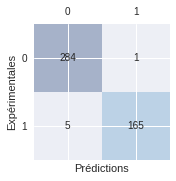


Résultats [test] :
- Précision : 0.9649
- AUC Score : 0.997024
- Matrice de confusion :


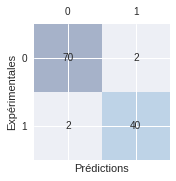

In [50]:
gs_svm.fit(X_train, y_train)
svm_best = gs_svm.best_estimator_
show_scores(svm_best, X_train, y_train, "train")
show_scores(svm_best, X_test, y_test, "test")

Application au modèle arbre de décision


Résultats [train] :
- Précision : 1
- AUC Score : 1.000000
- Matrice de confusion :


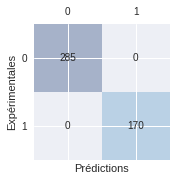


Résultats [test] :
- Précision : 0.9386
- AUC Score : 0.936508
- Matrice de confusion :


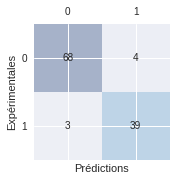

In [51]:
gs_tree.fit(X_train, y_train)
tree_best = gs_tree.best_estimator_
show_scores(tree_best, X_train, y_train, "train")
show_scores(tree_best, X_test, y_test, "test")

ROC AUC

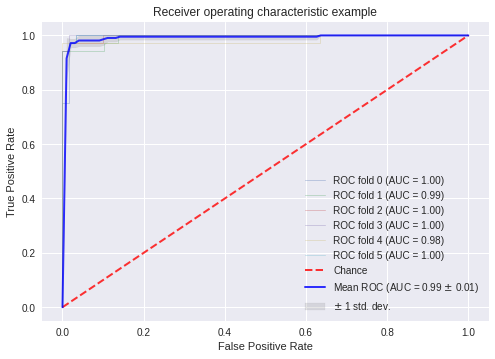

In [55]:
show_roc_cv(svm_best)

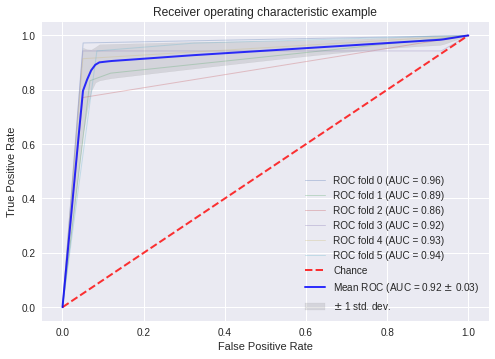

In [56]:
show_roc_cv(tree_best)

<a id='metrics'></a>